<a href="https://colab.research.google.com/github/WalterPerjenko/LW_Statistic/blob/main/%D0%A1%D0%BF%D1%80%D0%B8%D0%BD%D1%82_2_%D0%B3%D0%B5%D0%BD%D0%B5%D1%80%D0%B0%D1%82%D0%BE%D1%80%D1%8B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Нормальный генератор

In [4]:
import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp


def read_data(filename):
    df = pd.read_csv(filename, encoding='utf-8-sig')
    if len(df.columns) == 1 and any(s in df.columns[0] for s in (';', '\t')):
        df = pd.read_csv(filename, sep=None, engine='python', encoding='utf-8-sig')
    column = next((col for col in df if col.strip().lower() in ('logs', 'solubility')), None)
    if column is None:
        raise ValueError('В таблице нужен столбец LogS или Solubility (значения logS).')

    values = pd.to_numeric(df[column], errors='coerce').to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 20:
        raise ValueError('Недостаточно наблюдений (нужно хотя бы 20).')
    return values


def generate(values, n, rng):
    # Обратная эмпирическая функция распределения.
    sorted_values = np.sort(values)
    u = rng.random(n)
    indices = np.floor(u * len(sorted_values)).astype(int)
    return sorted_values[indices]


def metrics(values):
    return {
        'mean': np.mean(values),
        'std': np.std(values, ddof=1),
        'median': np.median(values),
        'q25': np.quantile(values, 0.25),
        'q75': np.quantile(values, 0.75),
    }


def run(filename, n=None, seed=42):
    values = read_data(filename)
    rng = np.random.default_rng(seed)

    # 80% для построения распределения, 20% для проверки.
    perm = rng.permutation(len(values))
    k = int(len(values) * 0.8)
    train = values[perm[:k]]
    test = values[perm[k:]]

    if n is None:
        n = len(test)
    if n < 1:
        raise ValueError('Число генерируемых значений должно быть положительным.')
    generated = generate(train, n, rng)

    output = Path('results')
    output.mkdir(exist_ok=True)
    pd.DataFrame({'LogS': generated}).to_csv(output / 'generated.csv', index=False)

    table = pd.DataFrame({'real': metrics(test), 'generated': metrics(generated)})
    table['difference'] = table['generated'] - table['real']
    table.to_csv(output / 'metrics.csv')

    ks = ks_2samp(test, generated)
    print(table.round(4))
    print(f'KS: D = {ks.statistic:.4f}; p = {ks.pvalue:.4f}')

    plt.figure(figsize=(8, 4))
    plt.hist(test, bins=30, density=True, alpha=0.5, label='Real')
    plt.hist(generated, bins=30, density=True, alpha=0.5, label='Generated')
    plt.xlabel('LogS')
    plt.ylabel('Density')
    plt.legend()
    plt.tight_layout()
    plt.savefig(output / 'comparison.png', dpi=150)
    plt.close()

    return table, ks


if __name__ == '__main__':
    parser = argparse.ArgumentParser()
    parser.add_argument('csv', help='CSV-файл AqSolDB')
    parser.add_argument('--n', type=int, default=None)
    parser.add_argument('--seed', type=int, default=42)
    args = parser.parse_args()
    run(args.csv, args.n, args.seed)

usage: colab_kernel_launcher.py [-h] [--n N] [--seed SEED] csv
colab_kernel_launcher.py: error: unrecognized arguments: -f


SystemExit: 2

Тестовый генератор

In [ ]:
import unittest

import numpy as np

from generator import generate, metrics


class GeneratorTests(unittest.TestCase):
    def setUp(self):
        self.data = np.random.default_rng(1).normal(-3, 1.5, 1000)

    def test_values(self):
        sample = generate(self.data, 500, np.random.default_rng(2))
        self.assertTrue(np.isin(sample, self.data).all())

    def test_seed(self):
        x = generate(self.data, 200, np.random.default_rng(42))
        y = generate(self.data, 200, np.random.default_rng(42))
        np.testing.assert_array_equal(x, y)

    def test_mean(self):
        sample = generate(self.data, 100000, np.random.default_rng(3))
        self.assertLess(abs(metrics(sample)['mean'] - metrics(self.data)['mean']), 0.03)


if __name__ == '__main__':
    unittest.main()

Квантильный генератор LogS

In [ ]:
Для метрики LogS был написан генератор случайных чисел на базе квантильного генератора

Двухвыборочный тест Колмогорова-Смирнова: stat=0.00721, p-value=0.95750


,Real_LogS,Generated_LogS,Diff
Mean,-2.88991,-2.90954,0.01964
Std,2.36815,2.36356,0.00459
Median,-2.61817,-2.62223,0.00405
Min,-13.17190,-11.94380,1.22810
Max,2.13768,2.09865,0.03903
Skewness,-0.55161,-0.53174,0.01987
Kurtosis,-0.06000,-0.10131,0.04131


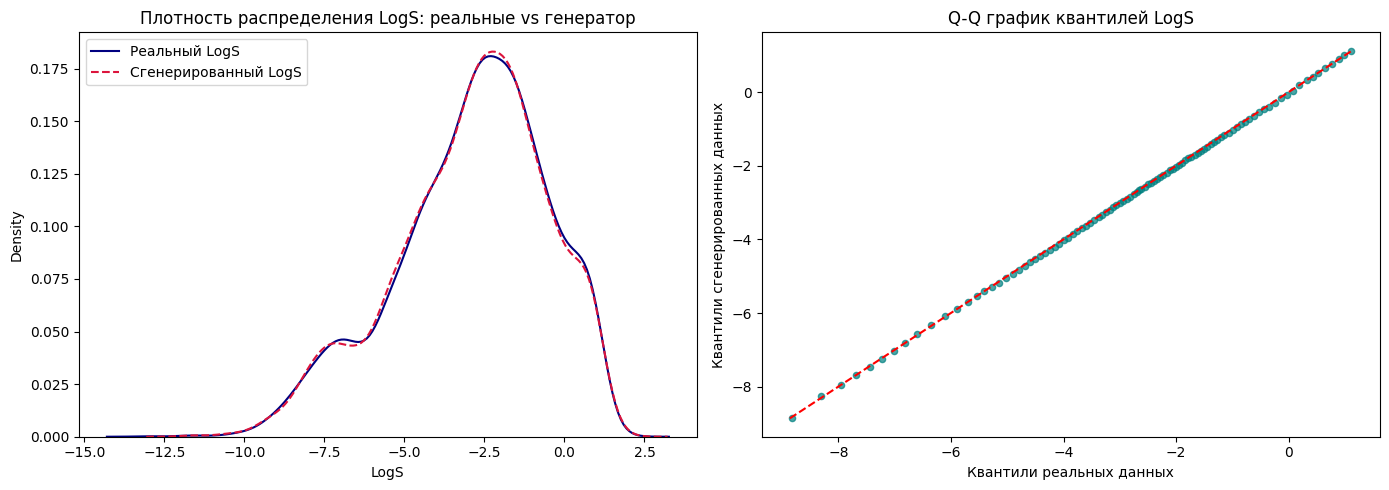

In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import kurtosis, skew
import seaborn as sns

URL = 'https://raw.githubusercontent.com/whitead/dmol-book/main/data/curated-solubility-dataset.csv'
df = pd.read_csv(URL)
logs_real = df['Solubility'].dropna().reset_index(drop=True)

def generate_logs_quantile(
    n_samples: int, source_series: pd.Series, seed: int = 42
) -> np.ndarray:
  """Генерирует выборку значений LogS (Solubility) методом квантильного преобразования."""
  if n_samples <= 0:
    raise ValueError('n_samples должен быть положительным целым числом.')
  clean_vals = source_series.dropna().to_numpy(dtype=float)
  if clean_vals.size == 0:
    raise ValueError('Исходная серия не содержит непустых значений.')

  rng = np.random.default_rng(seed)
  u = rng.random(n_samples)

  sorted_vals = np.sort(clean_vals)
  prob_grid = np.linspace(0.0, 1.0, sorted_vals.size, endpoint=True)
  return np.interp(u, prob_grid, sorted_vals)


logs_gen = generate_logs_quantile(
    n_samples=len(logs_real), source_series=logs_real, seed=42
)


def evaluate_logs_generator(real: pd.Series, gen: np.ndarray) -> pd.DataFrame:
  """Сравнивает описательные статистики и критерий Колмогорова-Смирнова для LogS."""
  real_arr = real.to_numpy(dtype=float)
  ks_stat, ks_p = stats.ks_2samp(real_arr, gen)

  metrics = pd.DataFrame(
      {
          'Real_LogS': [
              np.mean(real_arr),
              np.std(real_arr, ddof=1),
              np.median(real_arr),
              np.min(real_arr),
              np.max(real_arr),
              skew(real_arr, bias=True),
              kurtosis(real_arr, fisher=True, bias=True),
          ],
          'Generated_LogS': [
              np.mean(gen),
              np.std(gen, ddof=1),
              np.median(gen),
              np.min(gen),
              np.max(gen),
              skew(gen, bias=True),
              kurtosis(gen, fisher=True, bias=True),
          ],
      },
      index=['Mean', 'Std', 'Median', 'Min', 'Max', 'Skewness', 'Kurtosis'],
  )
  metrics['Diff'] = (metrics['Real_LogS'] - metrics['Generated_LogS']).abs()

  print(
      f'Двухвыборочный тест Колмогорова-Смирнова: stat={ks_stat:.5f},'
      f' p-value={ks_p:.5f}'
  )
  return metrics


assert logs_gen.shape == (len(logs_real),)
assert np.isfinite(logs_gen).all()
assert logs_gen.min() >= logs_real.min() - 1e-9
assert logs_gen.max() <= logs_real.max() + 1e-9

metrics_table = evaluate_logs_generator(logs_real, logs_gen)
display(metrics_table.round(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(logs_real, label='Реальный LogS', ax=axes[0], color='navy')
sns.kdeplot(
    logs_gen,
    label='Сгенерированный LogS',
    linestyle='--',
    ax=axes[0],
    color='crimson',
)
axes[0].set_title('Плотность распределения LogS: реальные vs генератор')
axes[0].set_xlabel('LogS')
axes[0].legend()

q_real = np.quantile(logs_real, np.linspace(0.01, 0.99, 99))
q_gen = np.quantile(logs_gen, np.linspace(0.01, 0.99, 99))
axes[1].scatter(q_real, q_gen, alpha=0.7, s=20, color='teal')
lims = [min(q_real.min(), q_gen.min()), max(q_real.max(), q_gen.max())]
axes[1].plot(lims, lims, 'r--', linewidth=1.5)
axes[1].set_title('Q-Q график квантилей LogS')
axes[1].set_xlabel('Квантили реальных данных')
axes[1].set_ylabel('Квантили сгенерированных данных')

plt.tight_layout()
plt.show()
